# 🌐 Tema 6.3: Grafos Multiplex (Múltiples Relaciones)
**Actividad: granja de trolls**

### Fase 1. Data Engineering
Convertimos el JSOn en una tabla maestra con 3 columnas: ``origen``, ``destino`` y ``relacion``. Cada fila es una arista del futuro grafo.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pandas as pd
import json 

# Abrir el json 
with open('../datasets/api_troll_farm.json', encoding="utf-8") as archivo:
    data = json.load(archivo)

# Abrir el json
df_base = pd.json_normalize(data)

# Hacer minusculas todas las cuentas
df_base["account_id"] = df_base["account_id"].str.lower()

# Hacer minusculas todas las cuentas en retweets
df_base["activity.retweets"] = df_base["activity.retweets"].apply(
    lambda lista: [usuario.lower() for usuario in lista]
    if isinstance(lista, list)
    else lista
)
df_base.head()

,account_id,metadata.last_ip,metadata.payment_hash,activity.retweets,metadata,activity
0,troll_bot_1,104.28.19.112,VISA-4455-XXXX-9090,"[real_user_11, troll_bot_1, troll_bot_1]",NaN,NaN
1,real_user_14,189.168.1.196,MC-8573-XXXX-1111,"[real_user_15, real_user_11]",NaN,NaN
2,real_user_13,189.168.1.184,None,"[real_user_3, real_user_9]",NaN,NaN
3,troll_bot_5,104.28.19.112,VISA-4455-XXXX-9090,"[real_user_12, troll_bot_1, troll_bot_5]",NaN,NaN
4,real_user_12,189.168.1.51,MC-4432-XXXX-1111,"[real_user_12, real_user_15]",NaN,NaN


Cada cuenta tiene una lista de usuarios a los que hace retweet. Con explode convertimos cada elementos de la lista en su propia fila. Luego eliminamos los nulos y los auto-retweets. Finalmente, etiquetamos la relación como ``"Retweet"``.

In [2]:
# Extraer relacion de retweets
df_rt = df_base[["account_id", "activity.retweets"]].explode(
    "activity.retweets"
)
df_rt = df_rt.rename(
    columns={"account_id": "origen", "activity.retweets": "destino"}
)

# Eliminación de nulos y auto-retweets 
df_rt = df_rt.dropna(subset=["destino"])
df_rt = df_rt[df_rt["origen"] != df_rt["destino"]]
df_rt["relacion"] = "Retweet"

df_rt.head()

,origen,destino,relacion
0,troll_bot_1,real_user_11,Retweet
1,real_user_14,real_user_15,Retweet
1,real_user_14,real_user_11,Retweet
2,real_user_13,real_user_3,Retweet
2,real_user_13,real_user_9,Retweet


La funcion ``obtener_pares_compartidos`` hace un self-merge de la tabla consigo misma sobre la columna indicada, así logramos que aparezca una fila por cada par de cuentas con el mismo valor. Luego filtramos por ``account_id`` para que descarte los pares consigo mismo, al igual que los duplicados espejo. Esto se aplica a la direccion ip y al payment hash de la tarjeta de credito.

In [3]:
# Relaciones compartidas (IP y tarjetas)
def obtener_pares_compartidos(df, columna, nombre_relacion):
    valido = df[["account_id", columna]].dropna()
    pares = pd.merge(valido, valido, on=columna)
    pares = pares[pares["account_id_x"] < pares["account_id_y"]]

    return pd.DataFrame({
        "origen": pares["account_id_x"],
        "destino": pares["account_id_y"],
        "relacion": nombre_relacion
    })

df_rip = obtener_pares_compartidos(df_base, "metadata.last_ip", "Mismo_IP")
df_rtarjetas = obtener_pares_compartidos(
    df_base, "metadata.payment_hash", "Misma_Tarjeta"
)

display(df_rip.head())
display(df_rtarjetas.head())

,origen,destino,relacion
1,troll_bot_1,troll_bot_5,Mismo_IP
3,troll_bot_1,troll_bot_4,Mismo_IP
4,troll_bot_1,troll_bot_6,Mismo_IP
5,troll_bot_1,troll_bot_3,Mismo_IP
6,troll_bot_1,troll_bot_2,Mismo_IP


,origen,destino,relacion
1,troll_bot_1,troll_bot_5,Misma_Tarjeta
3,troll_bot_1,troll_bot_4,Misma_Tarjeta
4,troll_bot_1,troll_bot_6,Misma_Tarjeta
5,troll_bot_1,troll_bot_3,Misma_Tarjeta
6,troll_bot_1,troll_bot_2,Misma_Tarjeta


Apilamos los 3 dataframes en una única tabla con todas las relaciones.

In [4]:
# Unir todos lod dfs
df_relaciones = pd.concat([df_rt, df_rip, df_rtarjetas], ignore_index=True)
print(df_relaciones)

          origen       destino       relacion
0    troll_bot_1  real_user_11        Retweet
1   real_user_14  real_user_15        Retweet
2   real_user_14  real_user_11        Retweet
3   real_user_13   real_user_3        Retweet
4   real_user_13   real_user_9        Retweet
..           ...           ...            ...
72   troll_bot_3   troll_bot_6  Misma_Tarjeta
73   troll_bot_2   troll_bot_5  Misma_Tarjeta
74   troll_bot_2   troll_bot_4  Misma_Tarjeta
75   troll_bot_2   troll_bot_6  Misma_Tarjeta
76   troll_bot_2   troll_bot_3  Misma_Tarjeta

[77 rows x 3 columns]


### Fase 2. El Grafo Multicapa
Contrsuimos el grafo con ``nx.from_pandas_edgelist`` y ``create_using=nx.MultiDiGraph()``. La columna relacion se guarda como atributo de la arista ``edge_attr`` y también como su clave.

In [5]:
# Instanciamos un Multigrafo
G = nx.from_pandas_edgelist(
    df_relaciones,
    source="origen",
    target="destino",
    edge_attr="relacion",
    edge_key="relacion",
    create_using=nx.MultiDiGraph(),
)

# Verificar
for u, v, key, data in G.edges(keys=True, data=True):
    print(f"{u} -> {v} | Relacion: {data['relacion']}")

troll_bot_1 -> real_user_11 | Relacion: Retweet
troll_bot_1 -> real_user_2 | Relacion: Retweet
troll_bot_1 -> troll_bot_5 | Relacion: Mismo_IP
troll_bot_1 -> troll_bot_5 | Relacion: Misma_Tarjeta
troll_bot_1 -> troll_bot_4 | Relacion: Mismo_IP
troll_bot_1 -> troll_bot_4 | Relacion: Misma_Tarjeta
troll_bot_1 -> troll_bot_6 | Relacion: Mismo_IP
troll_bot_1 -> troll_bot_6 | Relacion: Misma_Tarjeta
troll_bot_1 -> troll_bot_3 | Relacion: Mismo_IP
troll_bot_1 -> troll_bot_3 | Relacion: Misma_Tarjeta
troll_bot_1 -> troll_bot_2 | Relacion: Mismo_IP
troll_bot_1 -> troll_bot_2 | Relacion: Misma_Tarjeta
real_user_11 -> real_user_14 | Relacion: Retweet
real_user_11 -> real_user_6 | Relacion: Retweet
real_user_14 -> real_user_15 | Relacion: Retweet
real_user_14 -> real_user_11 | Relacion: Retweet
real_user_15 -> real_user_14 | Relacion: Retweet
real_user_15 -> real_user_13 | Relacion: Retweet
real_user_13 -> real_user_3 | Relacion: Retweet
real_user_13 -> real_user_9 | Relacion: Retweet
real_user_3

### Fase 3. Diseccionando el Grafo (Slicing)
Como solo nos interesa saber qué cuentas comparten la misma tarjeta, extraemos esa capa de las demás relaciones. Filtramos por ``relacion == 'Misma_Tarjeta'`` y eso lo metemos en un nx.Graph(). Luego ``nx.connected_components`` las agrupa por cuentas conectadas entre sí. 

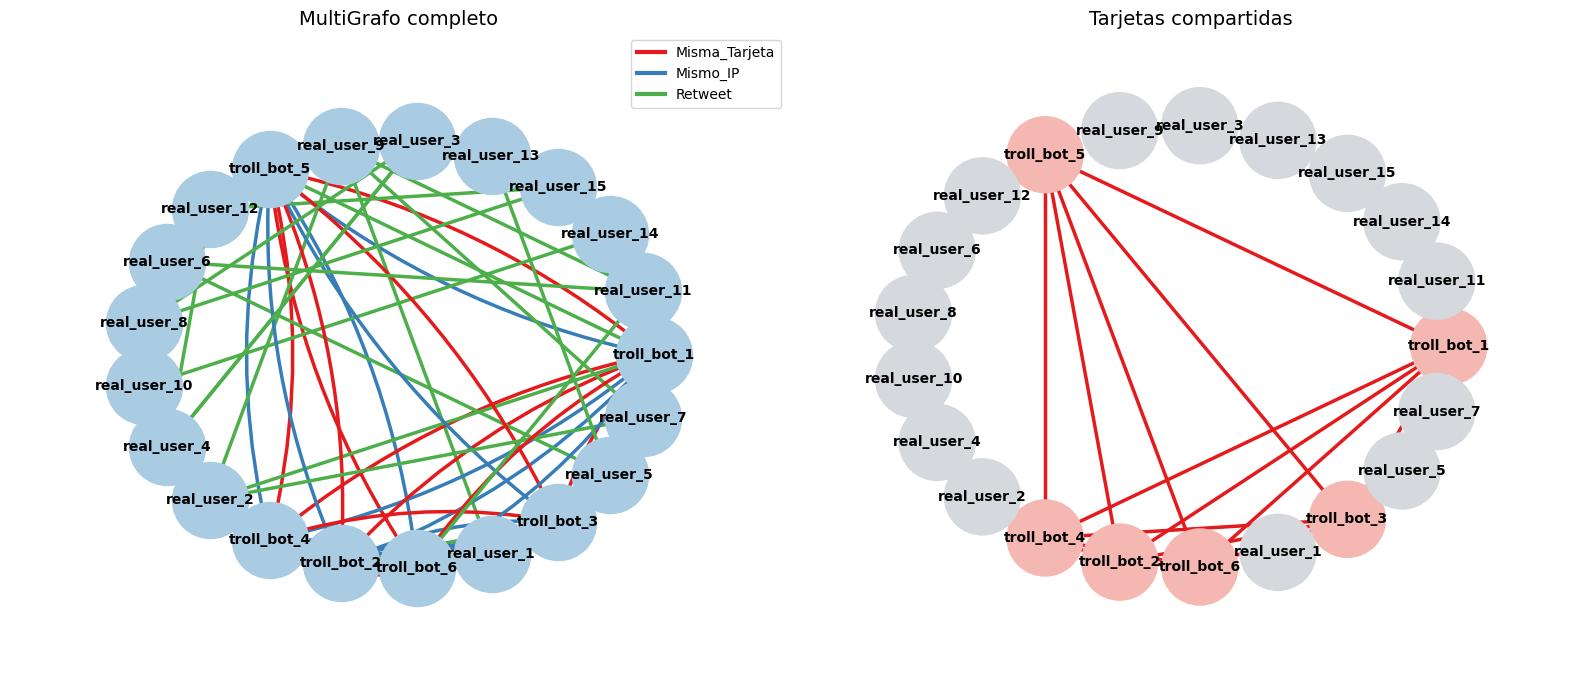

In [6]:
# Extraemos las capas
aristas_misma_tarjeta = [(u, v) for u, v, d in G.edges(data=True) if d.get('relacion') == 'Misma_Tarjeta']
G_tarjetas = nx.Graph()
G_tarjetas.add_edges_from(aristas_misma_tarjeta)
tribus = list(nx.connected_components(G_tarjetas))

# 🛠️ EL TRUCO VISUAL PARA MULTIGRAFOS: 
# Calculamos la posición (pos) UNA SOLA VEZ basándonos en los 4 nodos. 
# circular_layout los pone en un cuadrado perfecto, evitando que se aglomeren.
pos_fija = nx.circular_layout(G)

# Se tiene un color por tipo de relacion
relaciones = sorted({d.get('relacion') for _, _, d in G.edges(data=True)})
paleta = plt.cm.Set1.colors
color_rel = {r: paleta[i % len(paleta)] for i, r in enumerate(relaciones)}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Grafico del multigrafo completo
ax = axes[0]
nx.draw_networkx_nodes(G, pos_fija, node_color='#A9CCE3', node_size=3000, ax=ax)
nx.draw_networkx_labels(G, pos_fija, font_weight='bold', font_size=10, ax=ax)

for u, v in set(G.edges()):
    paralelas = list(G[u][v].items())
    m = len(paralelas)
    for i, (k, d) in enumerate(paralelas):
        rad = 0.25* (i - (m-1) / 2)
        nx.draw_networkx_edges(
            G, pos_fija, edgelist=[(u, v)],
            edge_color=[color_rel[d.get('relacion')]], width=2.5,
            arrows=True, arrowstyle='-',
            connectionstyle=f'arc3,rad={rad}',
            node_size=3000, ax=ax
        )

ax.legend(handles=[Line2D([0], [0], color=c, lw=3, label=r)
for r, c in color_rel.items()], loc='upper right')
ax.set_title('MultiGrafo completo', fontsize=14)
ax.margins(0.2)
ax.axis('off')

# Grafico del multigrafo con solo mismas tarjetas
ax = axes[1]
G_tarjetas.add_nodes_from(G.nodes())             # para que aparezcan todos los nodos
colores_tribu = ['#F5B7B1', '#ABEBC6', '#F9E79F', '#D7BDE2']
color_nodo = {n: '#D5D8DC' for n in G_tarjetas.nodes()}   # gris = sin tribu
for tribu, color in zip([t for t in tribus if len(t) > 1], colores_tribu):
    for n in tribu:
        color_nodo[n] = color

nx.draw(G_tarjetas, pos_fija, ax=ax, with_labels=True,
        node_color=[color_nodo[n] for n in G_tarjetas.nodes()],
        node_size=3000, font_weight='bold', font_size=10,
        edge_color=color_rel.get('Misma_Tarjeta', 'red'), width=2.5)
ax.set_title('Tarjetas compartidas', fontsize=14)
ax.margins(0.2)

plt.tight_layout()
plt.show()

# El veredicto 
### ¿Cuáles son los nombres exactos (account_id) de los bots que conforman el anillo de fraude?
Los account id de los bots son: troll_bot_1, troll_bot_2, troll_bot_3, troll_bot_4, troll_bot_5 y troll_bot_6.

### ¿Cuál es el Hash de la tarjeta de crédito comprometida que el equipo de soporte técnico debe bloquear ahora mismo?
El hash de la tarjeta de crédito comprometida es 'VISA-4455-XXXX-9090'.

### Si tuvieran que entrenar un modelo de predicción, ¿cómo le pasarían este descubrimiento al modelo tabular (La matriz X de entrenamiento)?
Se le pasaría un dataframe con una fila por cada nodo y columnas con las características de los usuarios reales y bots, como sus relaciones, hash de tarjeta e IP. La matriz X no tendría la etiqueta de si son bots o no, eso solo va en la y. Por lo mismo tampoco tendría el nombre de la cuenta o cualquier otro dato que delate inmediatamente que sea un bot.